# Tutorial: CommonRoad Route Planner

This tutorial demonstrates how the CommonRoad Route Planner package can be used to plan high-level routes for planning problems given in CommonRoad scenarios.

## 0. Preparation
* you have gone through the tutorial for **CommonRoad Input-Output**
* you have installed the [route planner](https://gitlab.lrz.de/tum-cps/commonroad-route-planner) package

Let's start with importing relevant modules and classes.

In [9]:
%matplotlib inline
%load_ext autoreload
%autoreload 2

import os
import sys
import numpy as np # Make sure numpy is imported

# add the root folder to python path
path_notebook = os.getcwd()
sys.path.append(os.path.join(path_notebook, "../"))

import matplotlib.pyplot as plt
from commonroad.common.file_reader import CommonRoadFileReader

from commonroad_route_planner.utility.visualization import visualize_route
from commonroad.visualization.mp_renderer import MPRenderer

# Import the Fast API module
import commonroad_route_planner.fast_api.fast_api as cr_rp_api

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 1. Loading CR Scenario and Planning Problem
In the next step, we load a CommonRoad scenario and its planning problem(s), for which the routes should be planned. The route planner handles **one planning problem** at a time; thus, we need to manually specify the planning problem for which the routes should be planned. In our case, we select the first planning problem in the planning problem set. The meaning of the symbols in a scenario is explained as follows:
* **Dot**: initial state of the planning problem projected onto the position domain
* **Blue rectangle**: dynamic obstacle
* **Yellow rectangle**: goal region projected onto the position domain

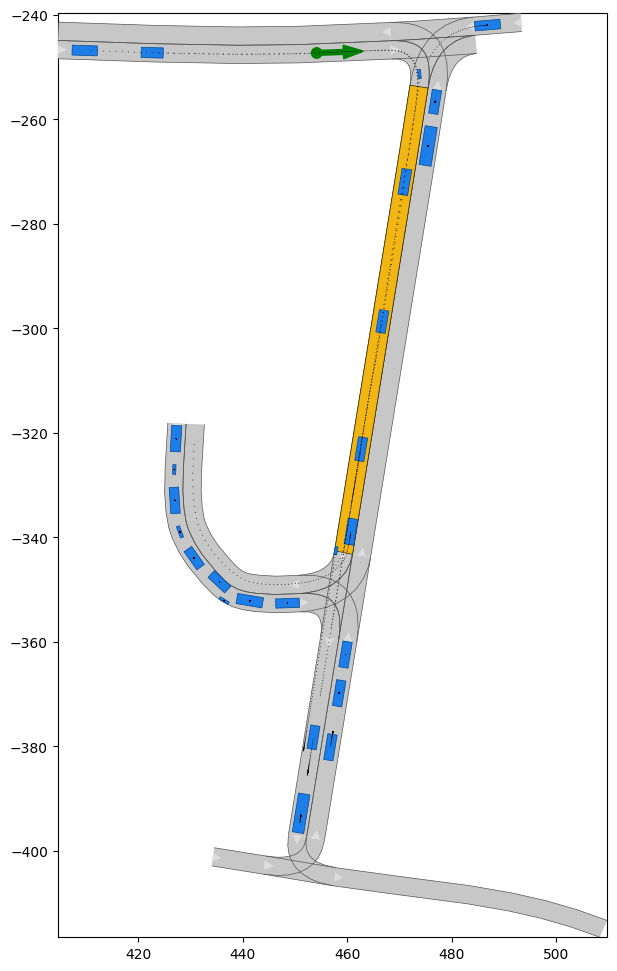

In [10]:
# load scenario
path_scenario = os.path.join(path_notebook, "../../scenarios/exercise/")
id_scenario = 'DEU_Flensburg-97_1_T-1'

# read in scenario and planning problem set
scenario, planning_problem_set = CommonRoadFileReader(path_scenario + id_scenario + '.xml').open()
# retrieve the first planning problem in the problem set
planning_problem = list(planning_problem_set.planning_problem_dict.values())[0]

# plot the scenario and the planning problem set
renderer = MPRenderer(figsize=(12, 12))

scenario.draw(renderer)
planning_problem.draw(renderer)

renderer.render()
plt.margins(0, 0)

## 2. Generating a Reference Path using the Fast API

We can use the `fast_api` module within the `commonroad-route-planner` package to generate a smoothed reference path.

In [11]:
# Generate the reference path using the Fast API function
try:
    reference_path_object = cr_rp_api.generate_reference_path_from_lanelet_network_and_planning_problem(
               lanelet_network=scenario.lanelet_network,
               planning_problem=planning_problem
     ) 
    print("Reference path generated successfully using Fast API.")
except Exception as e:
    print(f"Error generating reference path using Fast API: {e}")
    reference_path_object = None
reference_path_coords = reference_path_object.reference_path # Accessing the coordinates

Reference path generated successfully using Fast API.


## 3. Visualizing planning results

The reference path can be visualized using the `visualize_route` utility function. The code snippet below calls this function, passing the `reference_path_object` returned by the API, along with the `scenario` and `planning_problem`.

The code is currently configured to draw the smoothed reference path (red line) with `draw_reference_path=True` and *not* to draw the route lanelets (no green highlighting) by setting `draw_route_lanelets=False`.

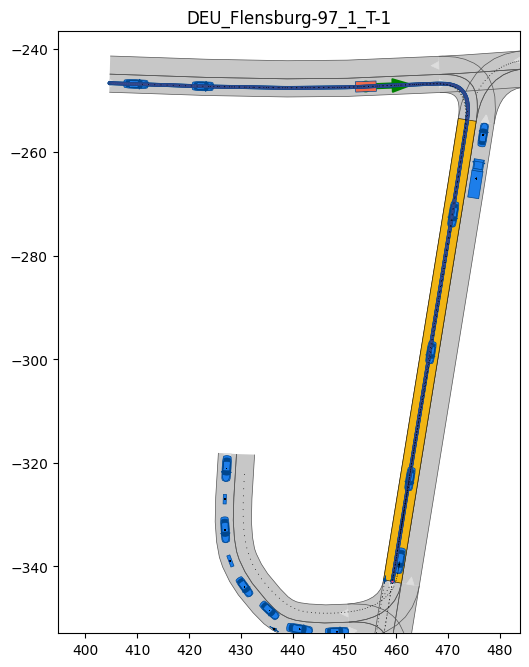

In [12]:
# Check if a reference path object was successfully generated before visualizing
if reference_path_object:
    # Visualize the reference path using the dedicated function
    # This function handles creating and showing the plot
    visualize_route(reference_path_object, # Use the object returned by the Fast API
                    scenario,
                    planning_problem,
                    draw_reference_path=True,  # Set to True as requested
                    draw_route_lanelets=False, # Set to True if you want to see the lanelets
                    size_x=6,
                    save_img=False)
else:
    print("Skipping visualization as no reference path object was generated.")